# LiDAR Sensors and Point Clouds

**Module 01 · Perception and Prediction** · Notebook 3 of 9

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/milinpatel07/Autonomous-Driving_AI-Safety-and-Security/blob/main/01_Perception/03_lidar_point_clouds.ipynb)

| Level | Prerequisites | Standards |
|---|---|---|
| Intermediate | [02 Sensor modalities](02_sensor_modalities.ipynb); basic linear algebra | IEC 60825-1:2014; ISO 8855:2011; ISO 21448:2022 |

**Author:** Milin Patel · Hochschule Kempten · MIT Licence

## Learning objectives

By the end of this notebook you will be able to:

1. Explain the physics of LiDAR ranging (pulsed time of flight, phase shift, FMCW) and the LiDAR range equation
2. Describe scanning mechanisms (spinning, mirror/prism scanning, MEMS, flash, OPA) and their trade-offs
3. Check datasheet-style density formulas against a real Velodyne HDL-64E scan from KITTI
4. Build a classical obstacle pipeline on real scans: bird's-eye-view image, RANSAC ground segmentation, DBSCAN clustering and oriented bounding boxes
5. Evaluate the pipeline against KITTI 3D ground truth: recall and points per object by distance, class and occlusion
6. Relate the measured weaknesses to SOTIF triggering conditions and to learned 3D detectors

## Setup

In [1]:
# Course toolkit (tables, formulas and real-data loaders). Installs automatically on Colab.
try:
    import avsafety
except ImportError:
    %pip install -q "avsafety[data] @ git+https://github.com/milinpatel07/Autonomous-Driving_AI-Safety-and-Security.git"
    import avsafety
from avsafety import data as D

In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from scipy.spatial import ConvexHull
from scipy.optimize import linear_sum_assignment
from scipy.spatial.transform import Rotation
from sklearn.cluster import DBSCAN
from IPython.display import display

rng = np.random.default_rng(42)
OKABE_ITO = ['#E69F00', '#56B4E9', '#009E73', '#F0E442', '#0072B2', '#D55E00', '#CC79A7', '#000000']
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': 0.3,
                     'axes.prop_cycle': plt.cycler(color=OKABE_ITO)})
C = 299_792_458.0   # speed of light [m/s]
print(f"NumPy {np.__version__}, avsafety {avsafety.__version__}")

NumPy 2.5.4, avsafety 1.1.0


### Data and licence

Sections 3.4 and 5 use real scans from the **KITTI object-detection benchmark** (Velodyne HDL-64E, 10 Hz, mounted 1.73 m above the road; Geiger et al., 2013) with its 3D bounding-box labels. `FRAMES` is the same seeded random draw as in [02 Sensor modalities](02_sensor_modalities.ipynb): 30 training frames with at least two cars and at least two pedestrians or cyclists. Each scan is about 1.9 MB and is fetched once, then cached.

In [3]:
print(D.attribution('KITTI'))
FRAMES = [35, 134, 217, 274, 462, 1134, 1868, 2096, 2227, 3078, 3677, 3687, 4170, 4283, 4292,
          4520, 4651, 4755, 4804, 4972, 5259, 5430, 5622, 5838, 5920, 5934, 6333, 6511, 6785, 6916]
SHOW = 3687               # showcase frame: cars and pedestrians from 5 to 42 m
GROUP = {'Car': 'Car', 'Van': 'Car', 'Truck': 'Car', 'Pedestrian': 'Pedestrian',
         'Person_sitting': 'Pedestrian', 'Cyclist': 'Cyclist'}       # Tram, Misc, DontCare not evaluated
CLASS_COLOURS = {'Car': OKABE_ITO[4], 'Pedestrian': OKABE_ITO[5], 'Cyclist': OKABE_ITO[0]}
try:
    show = D.kitti_object(SHOW)
except D.DataUnavailable as exc:
    raise SystemExit(f"KITTI could not be downloaded ({exc}). Run the notebook with internet access.")
print(f"Showcase frame {show.index}: {len(show.points):,} points, "
      f"{sum(l['type'] in GROUP for l in show.labels)} labelled cars/pedestrians/cyclists")

Data: KITTI Vision Benchmark Suite (Geiger et al., CVPR 2012 / IJRR 2013), CC BY-NC-SA 3.0, https://www.cvlibs.net/datasets/kitti/
Showcase frame 003687: 99,557 points, 9 labelled cars/pedestrians/cyclists


## 1. Physical principles

LiDAR (Light Detection and Ranging) measures distance by emitting laser light and analysing the reflected signal: **emission → reflection → detection → range computation**.

### 1.1 Pulsed time of flight (ToF)

The range follows from the round-trip time $\Delta t$:

$$ d = \frac{c\,\Delta t}{2} $$

A target at 100 m returns after $\Delta t = 200\,\text{m} / c \approx 667$ ns. The range resolution is set by the timing resolution: $\Delta d = c\,\Delta t_{res}/2$, so 1 cm requires $\Delta t_{res} \approx 67$ ps.

**Properties**
- Long range (> 200 m for long-range units at high reflectivity) and cm-level accuracy.
- Range is measured directly; **velocity must be inferred from successive frames** (FMCW LiDAR measures per-point radial velocity via the Doppler effect).
- Challenges: picosecond timing electronics, ambient light (sunlight), multipath, interference from other LiDARs.

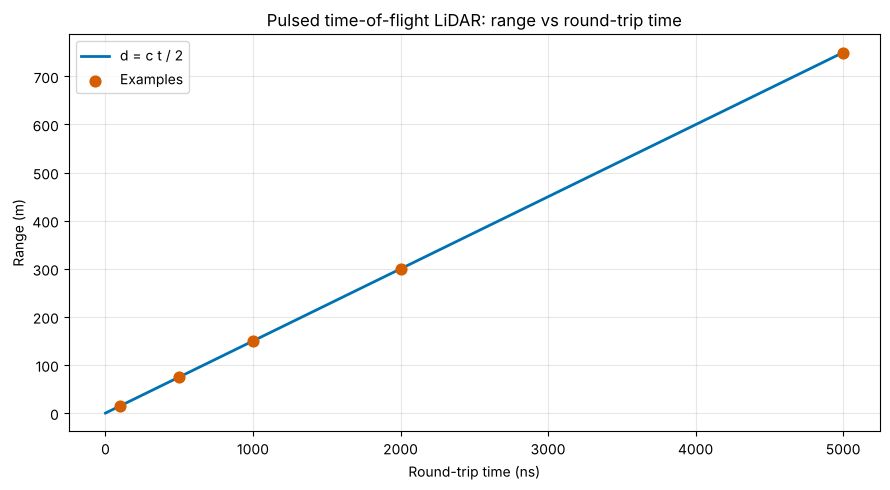

--- Time of flight (text summary) ---
    100 ns ->   14.99 m
    500 ns ->   74.95 m
   1000 ns ->  149.90 m
   2000 ns ->  299.79 m
   5000 ns ->  749.48 m
  Timing resolution for 1 cm range resolution: 67 ps


In [4]:
def tof_distance(travel_time_ns):
    """Range [m] from round-trip time [ns]."""
    return C * travel_time_ns * 1e-9 / 2

travel_times = np.array([100, 500, 1000, 2000, 5000])
distances = tof_distance(travel_times)
t = np.linspace(0, 5000, 200)

plt.figure(figsize=(9, 5))
plt.plot(t, tof_distance(t), color=OKABE_ITO[4], lw=2, label='d = c t / 2')
plt.scatter(travel_times, distances, color=OKABE_ITO[5], s=60, zorder=5, label='Examples')
plt.xlabel('Round-trip time (ns)'); plt.ylabel('Range (m)')
plt.title('Pulsed time-of-flight LiDAR: range vs round-trip time'); plt.legend()
plt.tight_layout(); plt.show()

print("--- Time of flight (text summary) ---")
for tt, dd in zip(travel_times, distances):
    print(f"  {tt:5.0f} ns -> {dd:7.2f} m")
print(f"  Timing resolution for 1 cm range resolution: {2*0.01/C*1e12:.0f} ps")

### 1.2 Phase shift (amplitude-modulated continuous wave)

For a sinusoidally modulated wave with modulation frequency $f$ and measured phase shift $\phi$:

$$ d = \frac{c\,\phi}{4\pi f}, \qquad d_{max} = \frac{c}{2f} $$

At $f = 10$ MHz the unambiguous range is 15 m. Several modulation frequencies are combined to resolve the ambiguity.

- **Pros:** high precision at short range (mm-level), lower peak power.
- **Cons:** limited unambiguous range (typically < 50 m without multi-frequency schemes); moving targets cause phase errors during the integration time.

### 1.3 FMCW (frequency-modulated continuous wave)

The laser frequency is swept (chirped); mixing the return with the outgoing light gives a beat frequency proportional to range, shifted by the Doppler frequency $2v_r/\lambda$. FMCW LiDAR therefore measures **range and radial velocity per point**, and is inherently resistant to interference from other sensors and sunlight. It typically uses 1550 nm lasers and coherent detection.

## 2. Scanning mechanisms

| Mechanism | How the beam is steered | Example products | Typical FOV (H) | Notes |
|---|---|---|---|---|
| **Spinning (rotating head)** | Whole laser/detector stack rotates | Velodyne HDL-64E (legacy), Ouster OS series, Hesai Pandar | 360° | Mature, surround view; moving parts |
| **Mirror / polygon scanning** | Rotating or oscillating mirrors | Luminar Iris; Hesai ATX | ~120° | Forward-facing, long range |
| **Risley prisms** | Two rotating wedge prisms | Livox | ~40–80° | Non-repetitive rosette pattern; coverage grows with integration time |
| **MEMS mirror** | Micro-mirror on a silicon chip | InnovizOne | ~100–120° | Few moving masses, compact |
| **Flash** | Whole scene illuminated at once; detector array | Short-range units | ~30–120° | No moving parts; short range (eye-safety power budget spread over FOV) |
| **Optical phased array (OPA)** | Phase-controlled emitter array | Mostly research / prototype stage | — | Fully solid-state |

Notes and corrections (as of October 2026):
- Velodyne merged with Ouster in February 2023 ([Ouster 10-K](https://www.sec.gov/Archives/edgar/data/1816581/000162828024013619/oust-20231231.htm)); Chinese suppliers such as Hesai and RoboSense now ship the largest volumes.
- Hesai's ATX (one-dimensional rotating mirror, ASIC-integrated lasers and detectors) is priced at about US\$200 in mass production since 2025 ([Reuters via LEDinside](https://www.ledinside.com/node/34820)). The cost trajectory is roughly ~US\$75k (HDL-64E, 2007) → ~US\$1k → ~US\$200.
- Luminar filed for Chapter 11 on 15 December 2025 after Volvo ended the EX90/ES90 supply agreement ([TechCrunch](https://techcrunch.com/2025/12/15/lidar-maker-luminar-files-for-bankruptcy)).
- Bosch ended its LiDAR development in 2023.
- Moving parts are a durability concern for automotive qualification; fewer or no moving parts generally improve robustness to vibration.

## 3. Specifications

### 3.1 Range and the LiDAR equation

Received power depends on transmit power $P_t$, target reflectivity $\rho$, atmospheric transmission $\tau$ (one way), receiver aperture area $A_r$, incidence angle $\alpha$ and distance $d$. For an **extended Lambertian target that fills the beam**, the beam divergence cancels:

$$ P_r = \frac{P_t\,\rho\,\tau^2\,A_r\cos\alpha}{\pi d^2} $$

For a **small target** (smaller than the beam footprint) the intercepted fraction itself falls with $d^2$, so $P_r \propto 1/d^4$. This is why datasheets quote range **at a stated reflectivity** (e.g. 10 %) — dark cars and dark clothing are the hard cases. Eye safety (IEC 60825-1, Class 1) caps $P_t$; 1550 nm lasers allow higher power than 905 nm but suffer stronger water absorption (rain, fog) and need costlier InGaAs detectors.

### 3.2 Accuracy, precision, resolution

- **Range accuracy** (systematic): typically ±2–5 cm; **precision** (random): ~1 cm at short range, degrading with distance and low reflectivity.
- **Angular resolution:** ~0.1–0.4° horizontal, ~0.1–2° vertical depending on the sensor.

### 3.3 Point density

For a spinning sensor with vertical FOV $\theta_v$ (radians), the scanned band at distance $d$ is a cylinder strip of area $(2\pi d)\cdot(d\,\theta_v)$. Points per revolution spread over this area:

$$ \rho_{points}(d) = \frac{N_{rev}}{2\pi d^2\,\theta_v} $$

**Worked example (HDL-64E as used in KITTI, 64 channels, about 0.18° azimuth step at 10 Hz ≈ 1.3 M points/s):** $N_{rev} = 2000 \times 64 = 128{,}000$; $\theta_v = 26.9° = 0.4695$ rad; at 10 m the band area is $(2\pi \cdot 10) \cdot (10 \cdot 0.4695) \approx 295\ \text{m}^2$, so the density is $128{,}000 / 295 \approx 430$ points/m². (Using the fraction 26.9°/360° instead of radians would understate the area by a factor of 2π — a common mistake.) Section 3.4 checks the azimuth step and the number of points against real KITTI scans.

Check of the worked example: 434 points/m^2 at 10 m


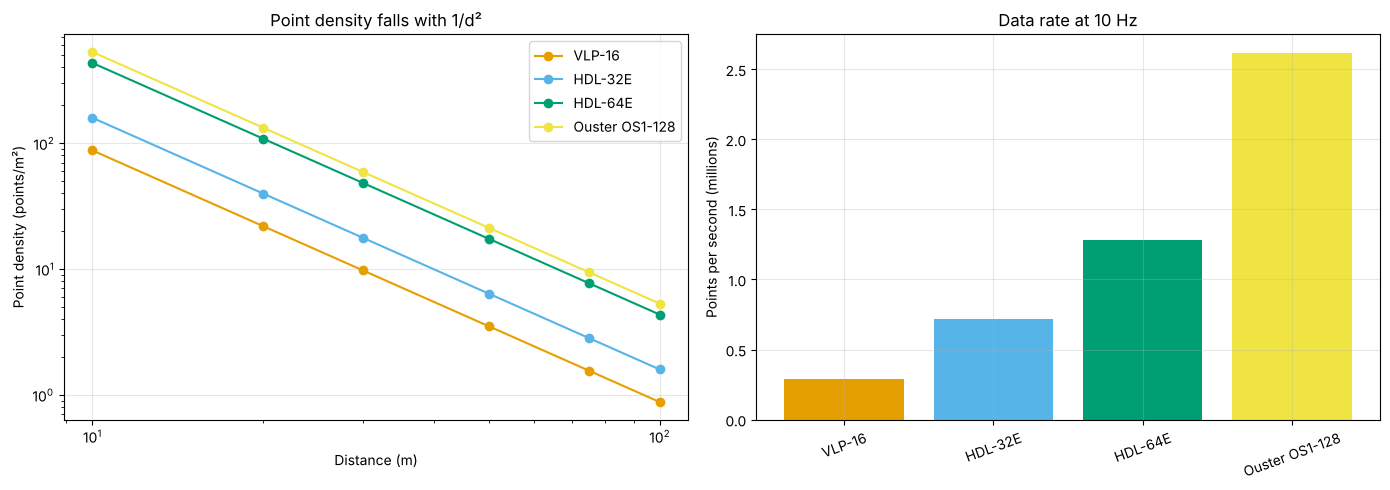

--- Point density (text summary) ---
  VLP-16          0.29 M pts/s | 10 m: 87.5, 20 m: 21.9, 30 m: 9.7, 50 m: 3.5, 75 m: 1.6, 100 m: 0.9 pts/m^2
  HDL-32E         0.72 M pts/s | 10 m: 159.0, 20 m: 39.7, 30 m: 17.7, 50 m: 6.4, 75 m: 2.8, 100 m: 1.6 pts/m^2
  HDL-64E         1.28 M pts/s | 10 m: 433.9, 20 m: 108.5, 30 m: 48.2, 50 m: 17.4, 75 m: 7.7, 100 m: 4.3 pts/m^2
  Ouster OS1-128  2.62 M pts/s | 10 m: 530.4, 20 m: 132.6, 30 m: 58.9, 50 m: 21.2, 75 m: 9.4, 100 m: 5.3 pts/m^2
  Going from 10 m to 100 m reduces density by a factor of 100 (= (100/10)^2).


In [5]:
def point_density(cfg, d):
    """Points per m^2 on a cylinder of radius d, and points per second."""
    pts_rev = int(round(360.0 / cfg['h_res_deg'])) * cfg['channels']
    pts_s = pts_rev * cfg['rotation_hz']
    area = (2 * np.pi * d) * (d * np.deg2rad(cfg['v_fov_deg']))
    return pts_rev / area, pts_s

# Nominal configurations at 10 Hz (azimuth step scales with spin rate; check the current datasheet).
# HDL-64E: azimuth step as measured on KITTI in section 3.4.
sensors = {
    'VLP-16':         {'channels': 16,  'rotation_hz': 10, 'h_res_deg': 0.2,   'v_fov_deg': 30.0},
    'HDL-32E':        {'channels': 32,  'rotation_hz': 10, 'h_res_deg': 0.16,  'v_fov_deg': 41.3},
    'HDL-64E':        {'channels': 64,  'rotation_hz': 10, 'h_res_deg': 0.18,  'v_fov_deg': 26.9},
    'Ouster OS1-128': {'channels': 128, 'rotation_hz': 10, 'h_res_deg': 0.176, 'v_fov_deg': 45.0},
}
print(f"Check of the worked example: {point_density(sensors['HDL-64E'], 10)[0]:.0f} points/m^2 at 10 m")

dist = np.array([10, 20, 30, 50, 75, 100])
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, cfg in sensors.items():
    axes[0].loglog(dist, [point_density(cfg, d)[0] for d in dist], 'o-', label=name)
axes[0].set_xlabel('Distance (m)'); axes[0].set_ylabel('Point density (points/m²)')
axes[0].set_title('Point density falls with 1/d²'); axes[0].legend()
pps = [point_density(c, 50)[1] for c in sensors.values()]
axes[1].bar(list(sensors), np.array(pps) / 1e6, color=OKABE_ITO[:4])
axes[1].set_ylabel('Points per second (millions)'); axes[1].set_title('Data rate at 10 Hz')
axes[1].tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.show()

print("--- Point density (text summary) ---")
for name, cfg in sensors.items():
    dens = [point_density(cfg, d)[0] for d in dist]
    print(f"  {name:15s} {point_density(cfg, 50)[1]/1e6:4.2f} M pts/s | " +
          ", ".join(f"{d} m: {v:.1f}" for d, v in zip(dist, dens)) + " pts/m^2")
ratio = point_density(sensors['HDL-64E'], 10)[0] / point_density(sensors['HDL-64E'], 100)[0]
print(f"  Going from 10 m to 100 m reduces density by a factor of {ratio:.0f} (= (100/10)^2).")

### 3.4 Check against a real scan

The formula above is a nominal upper bound. A real scan has fewer points (beams that hit the sky or a black, distant surface return nothing) and its beams are not evenly spaced. KITTI stores the points of one sweep ring by ring, so the 64 beams can be recovered from the azimuth wrap-around.

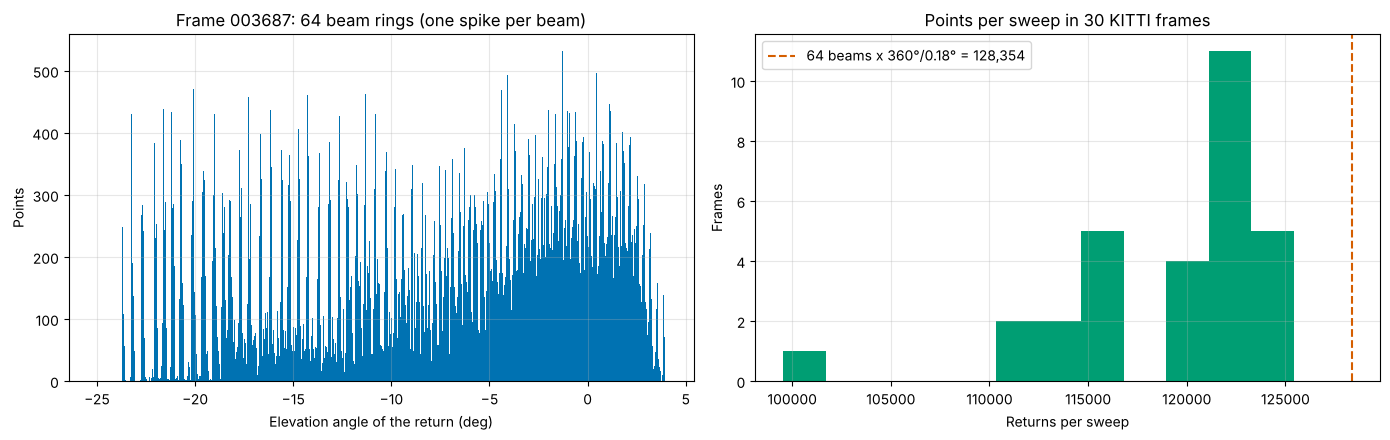

--- Real HDL-64E scan (text summary, measured) ---
  Rings found: 64; median azimuth step 0.180 deg
  Ring elevations from -23.7 to 2.8 deg; median spacing 0.40 deg (not uniform: finer near the horizon)
  Returns per sweep: mean 119,182 = 93 % of the nominal 128,354 (sky and weak targets return nothing)
  Closest ground return: 4.0 m; geometric blind radius h / tan(lowest beam) = 3.9 m - a child closer than this is seen only from the waist up


In [6]:
def rings(points):
    """Split a KITTI sweep into its laser rings (points are stored ring by ring)."""
    az = np.degrees(np.arctan2(points[:, 1], points[:, 0]))
    jumps = np.where(np.abs(np.diff(az)) > 90)[0] + 1
    return [s for s in np.split(np.arange(len(points)), jumps) if len(s) > 200], az

n_sweep, az_steps = [], []
for f in FRAMES:
    try:
        n_sweep.append(len(D.kitti_object(f, parts=('points',)).points))
    except D.DataUnavailable as exc:
        print(f"frame {f} skipped: {exc}")
p = show.points
ring_idx, az = rings(p)
el = np.degrees(np.arctan2(p[:, 2], np.hypot(p[:, 0], p[:, 1])))
ring_el = np.array([np.median(el[s]) for s in ring_idx])
az_step = np.median([np.median(np.abs(np.diff(az[s]))) for s in ring_idx])
nominal = len(ring_idx) * 360 / az_step

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].hist(el, bins=np.arange(-25, 4, 0.05), color=OKABE_ITO[4])
axes[0].set_xlabel('Elevation angle of the return (deg)'); axes[0].set_ylabel('Points')
axes[0].set_title(f'Frame {show.index}: {len(ring_idx)} beam rings (one spike per beam)')
axes[1].hist(n_sweep, bins=12, color=OKABE_ITO[2])
axes[1].axvline(nominal, color=OKABE_ITO[5], ls='--', label=f'64 beams x 360°/{az_step:.2f}° = {nominal:,.0f}')
axes[1].set_xlabel('Returns per sweep'); axes[1].set_ylabel('Frames'); axes[1].legend()
axes[1].set_title(f'Points per sweep in {len(n_sweep)} KITTI frames')
plt.tight_layout(); plt.show()

ground = np.abs(p[:, 2] + 1.73) < 0.3
r_min = np.percentile(np.hypot(p[ground, 0], p[ground, 1]), 0.5)
print("--- Real HDL-64E scan (text summary, measured) ---")
print(f"  Rings found: {len(ring_idx)}; median azimuth step {az_step:.3f} deg")
print(f"  Ring elevations from {ring_el.min():.1f} to {ring_el.max():.1f} deg; median spacing "
      f"{np.median(np.diff(np.sort(ring_el))):.2f} deg (not uniform: finer near the horizon)")
print(f"  Returns per sweep: mean {np.mean(n_sweep):,.0f} = {100 * np.mean(n_sweep) / nominal:.0f} % of the nominal {nominal:,.0f} "
      "(sky and weak targets return nothing)")
print(f"  Closest ground return: {r_min:.1f} m; geometric blind radius h / tan(lowest beam) = "
      f"{1.73 / np.tan(np.radians(-ring_el.min())):.1f} m - a child closer than this is seen only from the waist up")

### 3.5 Commercial sensors (vendor-reported, as of October 2026)

| Sensor | Type | Range (vendor) | FOV (H × V) | Status |
|---|---|---|---|---|
| Velodyne HDL-64E | Spinning, 64 ch | ~120 m | 360° × 26.9° | Legacy reference sensor (KITTI); Velodyne merged into Ouster (2023) |
| Ouster OS1-128 (Rev7) | Digital spinning (VCSEL + SPAD), 128 ch | ~90 m @ 10 %, ~200 m max | 360° × 45° | In production |
| Luminar Iris | Mirror scanning, 1550 nm | 250 m @ < 10 %, 600 m max | 120° × up to 26° | Luminar in Chapter 11 since Dec 2025; Volvo EX90/ES90 contract ended Nov 2025 |
| InnovizOne | MEMS | 250 m | up to 115° × 25° | Series production on BMW 7 Series / i7 (Personal Pilot L3, Germany) |
| Hesai ATX | 1D rotating mirror | — | — | ~US\$200, mass production since 2025 |

Sources: [Clearpath OS1 Rev7 page](https://store.clearpathrobotics.com/products/os1-rev-7); [Luminar Technologies (Wikipedia)](https://en.wikipedia.org/wiki/Luminar_Technologies); [Innoviz](https://innoviz.tech/innovizone); [IEEE Spectrum on BMW/Innoviz](https://spectrum.ieee.org/embargoed-until-7am-edt-thursday-25-april-bmw-will-use-solidstate-lidar-from-innoviz). Always use the current datasheet for engineering decisions.

## 4. Coordinate frames and extrinsic calibration

Points are measured in the **sensor frame**. Before fusion they are transformed into the vehicle frame or a camera frame (ISO 8855: x forward, y left, z up) using the **extrinsic calibration** — a rotation $R$ and translation $t$:

$$ \mathbf{p}_{target} = R\,\mathbf{p}_{sensor} + \mathbf{t} $$

KITTI ships the extrinsic from the Velodyne to the reference camera with every frame. Reading it is a useful sanity check: the rotation is almost exactly the axis change (x forward → z forward), and the translation is the mounting offset between the two sensors.

In [7]:
Tr = show.calib['Tr_velo_to_cam']
R_axes = np.array([[0, -1, 0], [0, 0, -1], [1, 0, 0]], float)     # LiDAR (x fwd, y left, z up) -> camera (x right, y down, z fwd)
residual = Rotation.from_matrix(R_axes.T @ Tr[:3, :3]).as_euler('xyz', degrees=True)
cam_in_velo = -Tr[:3, :3].T @ Tr[:3, 3]
print("Tr_velo_to_cam (3 x 4):\n", np.round(Tr[:3], 4))
print(f"Rotation beyond the pure axis change (roll, pitch, yaw about LiDAR axes): {np.round(residual, 2)} deg")
print(f"Camera position in the LiDAR frame: x = {cam_in_velo[0]:.2f} m, y = {cam_in_velo[1]:.2f} m, z = {cam_in_velo[2]:.2f} m")

Tr_velo_to_cam (3 x 4):
 [[ 7.500e-03 -1.000e+00 -6.000e-04 -4.100e-03]
 [ 1.480e-02  7.000e-04 -9.999e-01 -7.630e-02]
 [ 9.999e-01  7.500e-03  1.480e-02 -2.718e-01]]
Rotation beyond the pure axis change (roll, pitch, yaw about LiDAR axes): [-0.04  0.85 -0.43] deg
Camera position in the LiDAR frame: x = 0.27 m, y = -0.00 m, z = -0.07 m


Small rotation errors grow linearly with range: a yaw error $\delta\psi$ displaces a point at distance $d$ laterally by $\approx d\,\delta\psi$. The next cell evaluates this for a generic roof mount; [06 Sensor fusion](06_sensor_fusion.ipynb) perturbs the real KITTI extrinsic and measures what happens to camera–LiDAR association.

Sensor-frame points -> vehicle-frame points:
  [50.  0. -1.] -> [51.2  0.   0.8]
  [20.   3.5 -1. ] -> [21.2  3.5  0.8]
  [100.  -2.   0.] -> [101.2  -2.    1.8]


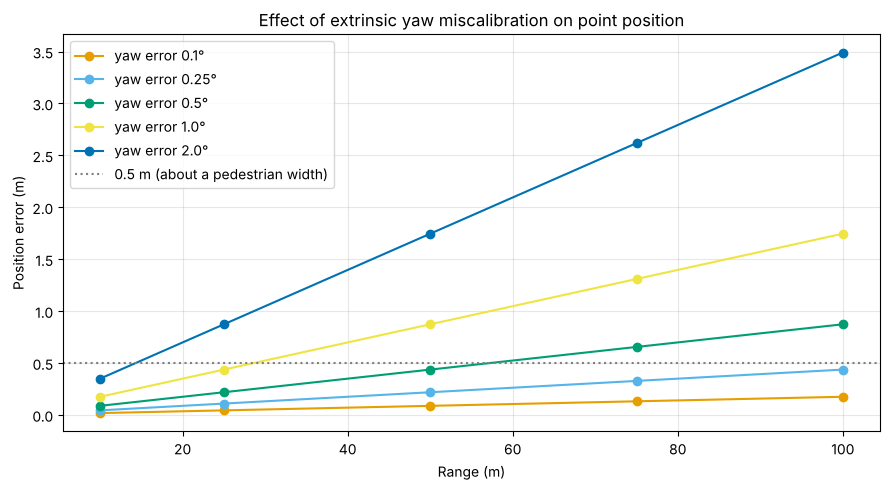

,10 m,25 m,50 m,75 m,100 m
0.1 deg,0.02,0.04,0.09,0.13,0.17
0.25 deg,0.04,0.11,0.22,0.33,0.44
0.5 deg,0.09,0.22,0.44,0.65,0.87
1.0 deg,0.17,0.44,0.87,1.31,1.75
2.0 deg,0.35,0.87,1.75,2.62,3.49


Largest yaw error that keeps the error below 0.5 m at 50 m: 0.5 deg
Motion distortion: at 108 km/h the vehicle moves 3.0 m during one 10 Hz sweep -> points must be motion-compensated (de-skewed) using odometry.


In [8]:
# Sensor mounted on the roof, 1.2 m ahead of the rear axle, 1.8 m above ground, with a nominal yaw of 0 deg
R_true = Rotation.from_euler('xyz', [0.0, 0.0, 0.0], degrees=True).as_matrix()
t_true = np.array([1.2, 0.0, 1.8])

def sensor_to_vehicle(p, R, t):
    return p @ R.T + t

p_sensor = np.array([[50.0, 0.0, -1.0], [20.0, 3.5, -1.0], [100.0, -2.0, 0.0]])
print("Sensor-frame points -> vehicle-frame points:")
for ps, pv in zip(p_sensor, sensor_to_vehicle(p_sensor, R_true, t_true)):
    print(f"  {ps} -> {np.round(pv, 2)}")

yaw_err = np.array([0.1, 0.25, 0.5, 1.0, 2.0])       # degrees
ranges = np.array([10, 25, 50, 75, 100])              # m
fig, ax = plt.subplots(figsize=(9, 5))
rows = []
for e in yaw_err:
    R_err = Rotation.from_euler('z', e, degrees=True).as_matrix() @ R_true
    lat = []
    for r in ranges:
        p = np.array([[r, 0.0, 0.0]])
        lat.append(np.linalg.norm(sensor_to_vehicle(p, R_err, t_true) - sensor_to_vehicle(p, R_true, t_true)))
    rows.append(lat)
    ax.plot(ranges, lat, 'o-', label=f'yaw error {e}°')
ax.axhline(0.5, color='grey', ls=':', label='0.5 m (about a pedestrian width)')
ax.set_xlabel('Range (m)'); ax.set_ylabel('Position error (m)')
ax.set_title('Effect of extrinsic yaw miscalibration on point position'); ax.legend()
plt.tight_layout(); plt.show()

err = pd.DataFrame(rows, index=[f'{e} deg' for e in yaw_err], columns=[f'{r} m' for r in ranges]).round(2)
display(err)
worst_ok = [e for e, row in zip(yaw_err, rows) if row[list(ranges).index(50)] < 0.5]
print(f"Largest yaw error that keeps the error below 0.5 m at 50 m: {max(worst_ok) if worst_ok else 'none'} deg")
v, sweep = 30.0, 0.1
print(f"Motion distortion: at {v*3.6:.0f} km/h the vehicle moves {v*sweep:.1f} m during one 10 Hz sweep -> "
      "points must be motion-compensated (de-skewed) using odometry.")

## 5. Point-cloud processing on real scans

A classic (non-learned) pipeline, still used as a class-agnostic **safety fallback** for obstacles of unknown type:

1. **Bird's-eye view (BEV)** — rasterise the cloud onto the ground plane (the input of many learned detectors).
2. **Ground segmentation** — fit a plane with RANSAC and remove points close to it.
3. **Clustering** — group the remaining points by Euclidean proximity (DBSCAN).
4. **Box fitting** — an oriented bounding box per cluster (minimum-area rectangle).
5. **Evaluation** — match clusters with the KITTI 3D labels.

### 5.1 Bird's-eye-view image

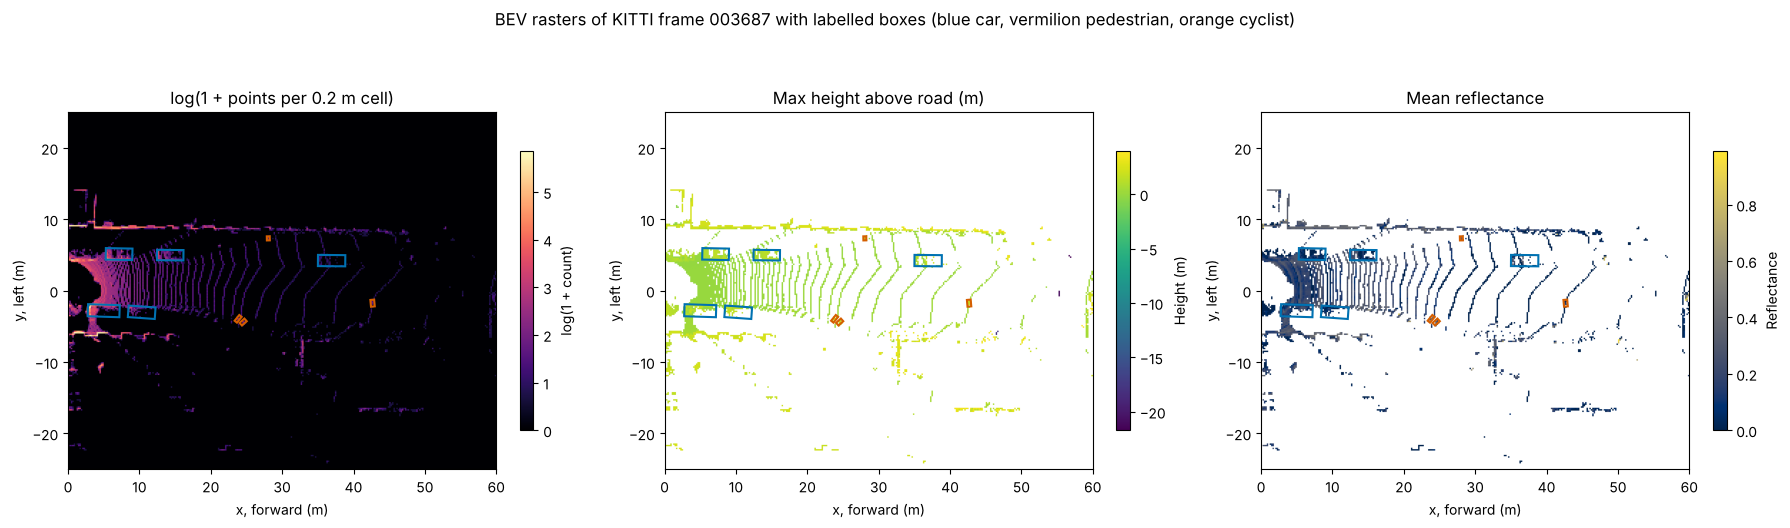

--- BEV (text summary) ---
  Grid 300 x 250 cells of 0.2 m; cells with returns: 4,473; cells with something > 0.3 m above the road: 2,189
  Objects appear as L-shapes (only the faces towards the sensor are hit) with empty shadows behind them; PointPillars-type detectors learn their features on exactly such a grid.


In [9]:
def bev_image(points, x_range=(0, 60), y_range=(-25, 25), res=0.2, z0=-1.73):
    """BEV rasters (rows = y from left to right, columns = x forward): log point count,
    maximum height above z0 and mean reflectance per cell."""
    m = ((points[:, 0] >= x_range[0]) & (points[:, 0] < x_range[1]) &
         (points[:, 1] >= y_range[0]) & (points[:, 1] < y_range[1]) & (points[:, 2] < z0 + 4))
    q = points[m]
    nx, ny = int(np.ptp(x_range) / res), int(np.ptp(y_range) / res)
    ix = ((q[:, 0] - x_range[0]) / res).astype(int)
    iy = ny - 1 - ((q[:, 1] - y_range[0]) / res).astype(int)
    count = np.zeros((ny, nx)); np.add.at(count, (iy, ix), 1)
    height = np.full((ny, nx), np.nan); order = np.argsort(q[:, 2])
    height[iy[order], ix[order]] = q[order, 2] - z0
    refl = np.zeros((ny, nx)); np.add.at(refl, (iy, ix), q[:, 3])
    refl = np.where(count > 0, refl / np.maximum(count, 1), np.nan)
    return np.log1p(count), height, refl

def footprint_velo(frame, lab):
    """Ground footprint (4 x 2) of a KITTI label in the LiDAR frame."""
    to_velo = np.linalg.inv(frame.calib['R0'] @ frame.calib['Tr_velo_to_cam'])
    corners = np.c_[D.box3d_corners(lab).T, np.ones(8)]
    return (to_velo @ corners.T).T[:4, :2]

ext = [0, 60, -25, 25]
layers = bev_image(show.points)
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, img, ttl, cmap, lab in zip(axes, layers, ['log(1 + points per 0.2 m cell)', 'Max height above road (m)',
                                                  'Mean reflectance'], ['magma', 'viridis', 'cividis'],
                                   ['log(1 + count)', 'Height (m)', 'Reflectance']):
    im = ax.imshow(img, extent=ext, origin='upper', cmap=cmap, vmin=0 if 'Height' in ttl else None,
                   vmax=3 if 'Height' in ttl else None, aspect='equal')
    for l in show.labels:
        if l['type'] in GROUP:
            fp = footprint_velo(show, l)
            ax.add_patch(Polygon(fp, fill=False, edgecolor=CLASS_COLOURS[GROUP[l['type']]], lw=1.5))
    ax.set_title(ttl); ax.set_xlabel('x, forward (m)'); ax.set_ylabel('y, left (m)'); ax.grid(False)
    fig.colorbar(im, ax=ax, fraction=0.03, label=lab)
fig.suptitle(f'BEV rasters of KITTI frame {show.index} with labelled boxes (blue car, vermilion pedestrian, orange cyclist)')
plt.tight_layout(); plt.show()
occupied = np.nan_to_num(layers[1]) > 0.3
print("--- BEV (text summary) ---")
print(f"  Grid {layers[0].shape[1]} x {layers[0].shape[0]} cells of 0.2 m; cells with returns: {np.isfinite(layers[1]).sum():,}; "
      f"cells with something > 0.3 m above the road: {occupied.sum():,}")
print("  Objects appear as L-shapes (only the faces towards the sensor are hit) with empty shadows behind them;"
      " PointPillars-type detectors learn their features on exactly such a grid.")

### 5.2 Ground segmentation with RANSAC

RANSAC (Fischler and Bolles, 1981) repeatedly fits a plane to three random points and keeps the plane with the most inliers; a least-squares refit on the inliers follows. We restrict candidates to low points near the vehicle and to near-horizontal planes. The fitted offset is a free check of the calibration: it should equal the mounting height of the sensor (1.73 m in KITTI).

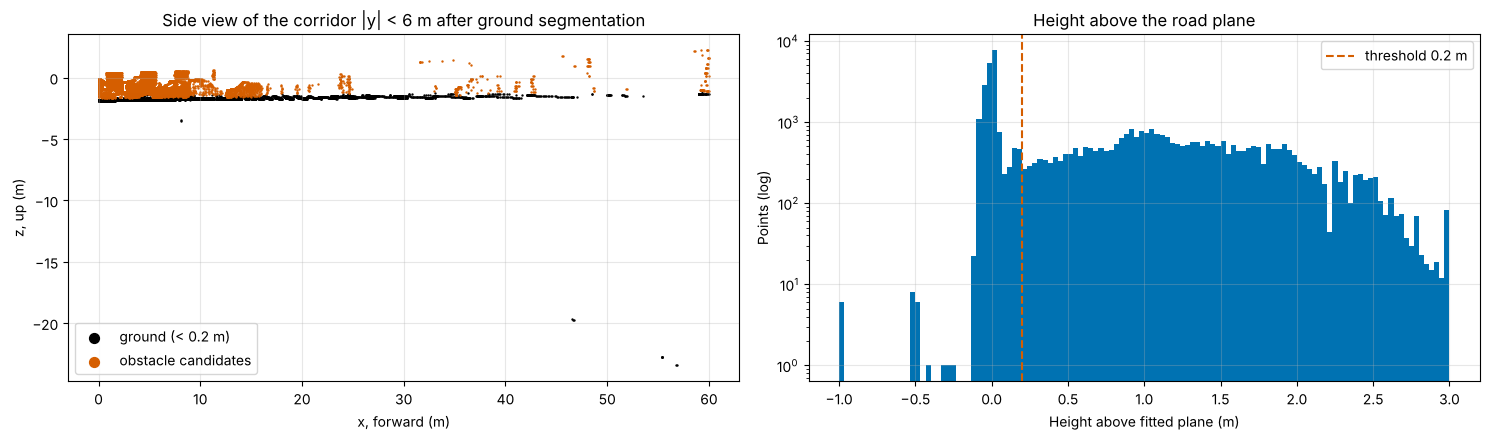

--- RANSAC ground plane (text summary) ---
  Normal [-0.006  0.027  1.   ], tilt 1.60 deg; sensor height above the plane 1.72 m (KITTI mounting height 1.73 m)
  Points within 0.2 m of the plane: 34,171 of 99,557 (34 %)
  One plane fits a flat street; on hills, kerbs and road camber, segment-wise planes or learned ground segmentation are needed - a residual of 0.2 m already hides a kerb-height obstacle.


In [10]:
def ransac_ground(points, rng, n_iter=150, thr=0.15):
    """Plane n.p + d = 0 (n pointing up) fitted to the road with RANSAC + least-squares refit."""
    cand = points[(points[:, 2] < -1.2) & (np.abs(points[:, 1]) < 20) & (points[:, 0] > 0) & (points[:, 0] < 50), :3]
    best, best_n = None, -1
    for _ in range(n_iter):
        s = cand[rng.choice(len(cand), 3, replace=False)]
        n = np.cross(s[1] - s[0], s[2] - s[0]); norm = np.linalg.norm(n)
        if norm < 1e-6 or abs(n[2]) / norm < 0.9:          # skip degenerate and steep planes
            continue
        n = n / norm; d = -n @ s[0]
        k = (np.abs(cand @ n + d) < thr).sum()
        if k > best_n:
            best, best_n = (n, d), k
    n, d = best
    inl = cand[np.abs(cand @ n + d) < thr]
    a, b, c = np.linalg.lstsq(np.c_[inl[:, :2], np.ones(len(inl))], inl[:, 2], rcond=None)[0]   # z = a x + b y + c
    n = np.array([-a, -b, 1.0]); norm = np.linalg.norm(n)
    return n / norm, -c / norm

plane = ransac_ground(show.points, rng)
h_above = show.points[:, :3] @ plane[0] + plane[1]
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
side = (np.abs(show.points[:, 1]) < 6) & (show.points[:, 0] > 0) & (show.points[:, 0] < 60)
for m, col, lab in [(h_above < 0.2, OKABE_ITO[7], 'ground (< 0.2 m)'), (h_above >= 0.2, OKABE_ITO[5], 'obstacle candidates')]:
    axes[0].scatter(show.points[side & m, 0], show.points[side & m, 2], s=0.5, color=col, label=lab)
axes[0].set_xlabel('x, forward (m)'); axes[0].set_ylabel('z, up (m)'); axes[0].legend(markerscale=10)
axes[0].set_title('Side view of the corridor |y| < 6 m after ground segmentation')
axes[1].hist(np.clip(h_above[(show.points[:, 0] > 0) & (show.points[:, 0] < 50)], -1, 3), bins=120, color=OKABE_ITO[4])
axes[1].axvline(0.2, color=OKABE_ITO[5], ls='--', label='threshold 0.2 m')
axes[1].set_yscale('log'); axes[1].set_xlabel('Height above fitted plane (m)'); axes[1].set_ylabel('Points (log)')
axes[1].set_title('Height above the road plane'); axes[1].legend()
plt.tight_layout(); plt.show()

tilt = np.degrees(np.arccos(plane[0][2]))
print("--- RANSAC ground plane (text summary) ---")
print(f"  Normal {np.round(plane[0], 3)}, tilt {tilt:.2f} deg; sensor height above the plane {plane[1]:.2f} m "
      "(KITTI mounting height 1.73 m)")
print(f"  Points within 0.2 m of the plane: {(np.abs(h_above) < 0.2).sum():,} of {len(h_above):,} "
      f"({100 * (np.abs(h_above) < 0.2).mean():.0f} %)")
print("  One plane fits a flat street; on hills, kerbs and road camber, segment-wise planes or learned ground"
      " segmentation are needed - a residual of 0.2 m already hides a kerb-height obstacle.")

### 5.3 DBSCAN clustering and oriented boxes

Points between 0.25 m and 3 m above the road, within 55 m ahead and 30 m to each side, are clustered in the ground plane with DBSCAN (Ester et al., 1996): a point with at least `min_samples` neighbours within `eps` starts or extends a cluster. For each cluster, the **minimum-area rectangle** of its convex hull gives an oriented box. Clusters longer than 12 m (walls, hedges) or lower than 0.5 m (kerbs) are discarded as non-objects.

Clustering took 2.1 s: 56 clusters, 54 object-like


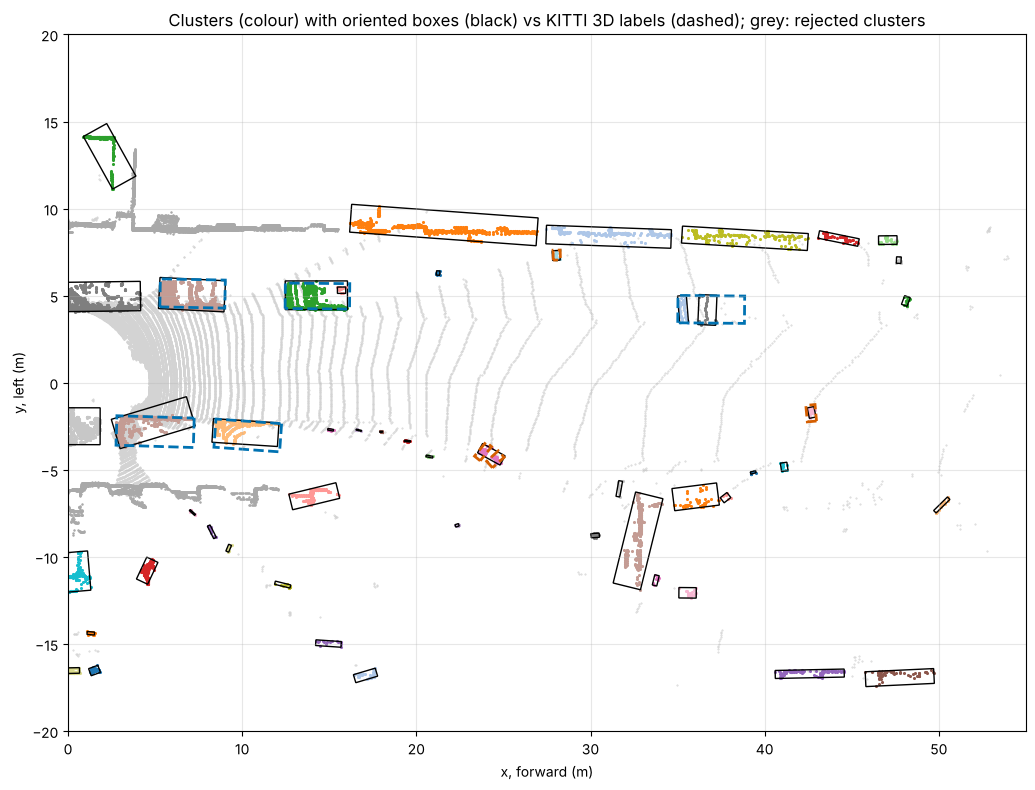

In [11]:
EPS, MIN_SAMPLES = 0.5, 8

def min_area_rect(xy):
    """Oriented minimum-area rectangle: centre (2,), (length, width), yaw (rad)."""
    if len(xy) < 3:
        return xy.mean(0), (0.1, 0.1), 0.0
    try:
        hull = xy[ConvexHull(xy).vertices]
    except Exception:                                   # collinear points
        return xy.mean(0), (np.ptp(xy[:, 0]) + 0.1, 0.1), 0.0
    best = None
    for i in range(len(hull)):
        e = hull[(i + 1) % len(hull)] - hull[i]; ang = np.arctan2(e[1], e[0])
        R = np.array([[np.cos(ang), np.sin(ang)], [-np.sin(ang), np.cos(ang)]])
        q = hull @ R.T; lo, hi = q.min(0), q.max(0)
        if best is None or np.prod(hi - lo) < best[0]:
            best = (np.prod(hi - lo), R.T @ ((lo + hi) / 2), hi - lo, ang)
    _, centre, size, ang = best
    if size[1] > size[0]:
        size, ang = size[::-1], ang + np.pi / 2
    return centre, (float(size[0]), float(size[1])), float(ang)

def rect_corners(centre, size, yaw):
    l, w = size
    c, s = np.cos(yaw), np.sin(yaw)
    loc = np.array([[l, w], [l, -w], [-l, -w], [-l, w]]) / 2
    return loc @ np.array([[c, s], [-s, c]]) + centre

def lidar_objects(points, rng):
    """Ground removal + DBSCAN + oriented boxes. Returns a list of cluster dicts and the plane."""
    plane = ransac_ground(points, rng)
    hz = points[:, :3] @ plane[0] + plane[1]
    m = (hz > 0.25) & (hz < 3.0) & (points[:, 0] > 0) & (points[:, 0] < 55) & (np.abs(points[:, 1]) < 30)
    q, hq = points[m], hz[m]
    lab = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit_predict(q[:, :2])
    out = []
    for k in range(lab.max() + 1):
        sel = lab == k
        centre, size, yaw = min_area_rect(q[sel, :2])
        out.append({'points': q[sel], 'centre': centre, 'size': size, 'yaw': yaw,
                    'height': float(hq[sel].max()), 'n': int(sel.sum()),
                    'object_like': size[0] <= 12 and hq[sel].max() >= 0.5})
    return out, plane

t0 = time.time()
clusters, _ = lidar_objects(show.points, rng)
print(f"Clustering took {time.time() - t0:.1f} s: {len(clusters)} clusters, "
      f"{sum(c['object_like'] for c in clusters)} object-like")

fig, ax = plt.subplots(figsize=(15, 8))
ax.scatter(show.points[:, 0], show.points[:, 1], s=0.2, color='lightgrey')
cmap = plt.get_cmap('tab20')
for k, c in enumerate(clusters):
    if not c['object_like']:
        ax.scatter(c['points'][:, 0], c['points'][:, 1], s=0.5, color='darkgrey'); continue
    ax.scatter(c['points'][:, 0], c['points'][:, 1], s=1.5, color=cmap(k % 20))
    ax.add_patch(Polygon(rect_corners(c['centre'], c['size'], c['yaw']), fill=False, edgecolor='black', lw=1))
for l in show.labels:
    if l['type'] in GROUP:
        ax.add_patch(Polygon(footprint_velo(show, l), fill=False, ls='--', lw=2,
                             edgecolor=CLASS_COLOURS[GROUP[l['type']]]))
ax.set_xlim(0, 55); ax.set_ylim(-20, 20); ax.set_aspect('equal')
ax.set_xlabel('x, forward (m)'); ax.set_ylabel('y, left (m)')
ax.set_title('Clusters (colour) with oriented boxes (black) vs KITTI 3D labels (dashed); grey: rejected clusters')
plt.tight_layout(); plt.show()

### 5.4 Comparing clusters with KITTI 3D ground truth (30 frames)

We evaluate all labelled cars, vans, trucks, pedestrians and cyclists inside the processed region (up to 55 m ahead). We match clusters to labelled objects one-to-one (Hungarian algorithm) on the distance between box centres in BEV, accepting matches closer than 2 m. For each match we also compute the **BEV IoU** of the cluster box with the labelled box. The labels are *amodal*: they describe the whole car even when only its rear is visible, so a cluster box drawn around visible points is systematically smaller.

A note on precision: KITTI labels only cars, vans, trucks, pedestrians, cyclists, trams and "misc" objects that are visible in the camera image. A cluster without a matching label is therefore often a real object outside the label taxonomy (pole, tree, parked bicycle, bollard) — a false positive for a benchmark, but a genuine obstacle for an emergency-braking function. We report recall and count unmatched clusters without calling them false alarms.

In [12]:
def polygon_area(p):
    return 0.5 * abs(np.dot(p[:, 0], np.roll(p[:, 1], 1)) - np.dot(p[:, 1], np.roll(p[:, 0], 1)))

def clip_polygon(subject, clip):
    """Sutherland-Hodgman clipping of a convex polygon by a convex, counter-clockwise polygon."""
    out = list(subject)
    for i in range(len(clip)):
        a, b = clip[i], clip[(i + 1) % len(clip)]
        inp, out = out, []
        inside = lambda p: (b[0] - a[0]) * (p[1] - a[1]) - (b[1] - a[1]) * (p[0] - a[0]) >= 0
        for j in range(len(inp)):
            p, q = inp[j], inp[(j + 1) % len(inp)]
            if inside(q):
                if not inside(p):
                    out.append(_intersect(p, q, a, b))
                out.append(q)
            elif inside(p):
                out.append(_intersect(p, q, a, b))
        if not out:
            return np.zeros((0, 2))
    return np.array(out)

def _intersect(p, q, a, b):
    d1, d2 = q - p, b - a
    t = ((a[0] - p[0]) * d2[1] - (a[1] - p[1]) * d2[0]) / (d1[0] * d2[1] - d1[1] * d2[0] + 1e-12)
    return p + t * d1

def ccw(p):
    signed = np.dot(p[:, 0], np.roll(p[:, 1], -1)) - np.dot(p[:, 1], np.roll(p[:, 0], -1))
    return p if signed > 0 else p[::-1]

def bev_iou(p1, p2):
    p1, p2 = ccw(p1), ccw(p2)
    inter = clip_polygon(p1, p2)
    a = polygon_area(inter) if len(inter) >= 3 else 0.0
    return a / (polygon_area(p1) + polygon_area(p2) - a)

def points_in_label(rect, lab, margin=0.1):
    ry = lab['rotation_y']
    rot = np.array([[np.cos(ry), 0, np.sin(ry)], [0, 1, 0], [-np.sin(ry), 0, np.cos(ry)]])
    loc = (rect - np.array([lab['x'], lab['y'], lab['z']])) @ rot
    return ((np.abs(loc[:, 0]) <= lab['l'] / 2 + margin) & (loc[:, 1] <= margin) &
            (loc[:, 1] >= -lab['h'] - margin) & (np.abs(loc[:, 2]) <= lab['w'] / 2 + margin))

GATE_M = 2.0
rows, n_unmatched, t0 = [], 0, time.time()
for f in FRAMES:
    try:
        fk = D.kitti_object(f, parts=('points', 'labels', 'calib'))
    except D.DataUnavailable as exc:
        print(f"frame {f} skipped: {exc}"); continue
    cl, _ = lidar_objects(fk.points, rng)
    cl = [c for c in cl if c['object_like']]
    rect = fk.velo_to_rect(fk.points)
    gts = [l for l in fk.labels if l['type'] in GROUP]
    fps = [footprint_velo(fk, l) for l in gts]
    keep = [k for k, fp in enumerate(fps) if fp.mean(0)[0] < 55 and abs(fp.mean(0)[1]) < 30]   # processed region
    gts, fps = [gts[k] for k in keep], [fps[k] for k in keep]
    M = np.array([[np.linalg.norm(c['centre'] - fp.mean(0)) for fp in fps] for c in cl]).reshape(len(cl), len(gts))
    matched = {}
    if M.size:
        for i, j in zip(*linear_sum_assignment(M)):
            if M[i, j] <= GATE_M:
                matched[j] = i
    # clusters whose centre lies within any label (incl. Misc, Tram, DontCare-free) are not "unlabelled"
    for i, c in enumerate(cl):
        if i in matched.values():
            continue
        near = [np.linalg.norm(c['centre'] - footprint_velo(fk, l).mean(0)) for l in fk.labels if l['type'] != 'DontCare']
        n_unmatched += (min(near) if near else 99) > GATE_M and (abs(c['centre'][1]) / max(c['centre'][0], 0.1) < 0.87)
    for j, (l, fp) in enumerate(zip(gts, fps)):
        i = matched.get(j)
        rows.append({'frame': f, 'class': GROUP[l['type']], 'distance_m': float(np.hypot(l['x'], l['z'])),
                     'occluded': l['occluded'], 'truncated': l['truncated'],
                     'lidar_points': int(points_in_label(rect, l).sum()), 'detected': i is not None,
                     'centre_error_m': M[i, j] if i is not None else np.nan,
                     'bev_iou': bev_iou(rect_corners(cl[i]['centre'], cl[i]['size'], cl[i]['yaw']), fp) if i is not None else np.nan,
                     'n_clusters_on_object': int(sum(points_in_label(fk.velo_to_rect(c['points']), l).mean() > 0.5 for c in cl))})
ev = pd.DataFrame(rows)
print(f"Evaluated {ev['frame'].nunique()} frames in {time.time() - t0:.0f} s: {len(ev)} labelled objects, "
      f"{int(n_unmatched)} object-like clusters in the camera's field of view without any label "
      "(facade and fence fragments, vegetation, poles, parked bicycles: compare the BEV figure above)")

Evaluated 30 frames in 75 s: 247 labelled objects, 955 object-like clusters in the camera's field of view without any label (facade and fence fragments, vegetation, poles, parked bicycles: compare the BEV figure above)


class,Car,Cyclist,Pedestrian
range,,,
0-15 m,97 % (n=33),80 % (n=15),68 % (n=19)
15-30 m,98 % (n=45),89 % (n=18),76 % (n=42)
30-45 m,88 % (n=43),100 % (n=4),62 % (n=8)
>45 m,76 % (n=17),100 % (n=1),100 % (n=2)


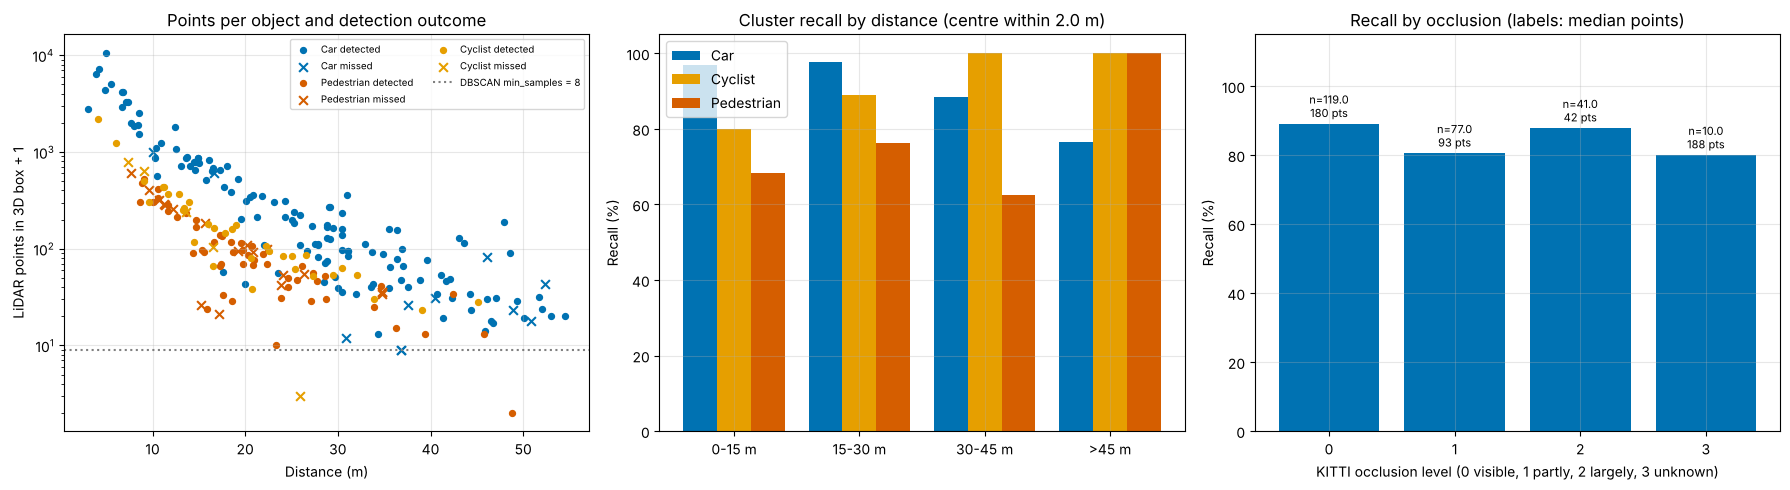

--- Cluster pipeline vs KITTI ground truth (text summary, measured) ---
  Overall recall 86 % (212 of 247); Car 92 %, Pedestrian 73 %, Cyclist 87 %
  Recall within 30 m: 87 %; beyond 30 m: 84 %
  Missed objects: median 82 points; detected: median 112 points
  Points per object fall with distance as d^-2.4 (Car), d^-2.2 (Pedestrian), d^-2.1 (Cyclist)
  Matched clusters: median centre error 0.37 m, median BEV IoU 0.37 (cars 0.33) - cluster boxes cover only the visible part
  Objects split over 2+ clusters (over-segmentation): 28; objects with no cluster of their own (merged or missed): 44
  Recall by occlusion level: 0: 89 %, 1: 81 %, 2: 88 %, 3: 80 %


In [13]:
ev['range'] = pd.cut(ev['distance_m'], [0, 15, 30, 45, 100], labels=['0-15 m', '15-30 m', '30-45 m', '>45 m'])
rec = ev.pivot_table(index='range', columns='class', values='detected', aggfunc='mean', observed=True) * 100
cnt = ev.pivot_table(index='range', columns='class', values='detected', aggfunc='size', observed=True)
display((rec.round(0).astype('Int64').astype(str) + ' % (n=' + cnt.astype('Int64').astype(str) + ')').fillna('-'))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for cls, col in CLASS_COLOURS.items():
    s = ev[ev['class'] == cls]
    axes[0].scatter(s.loc[s['detected'], 'distance_m'], s.loc[s['detected'], 'lidar_points'] + 1, s=18, color=col,
                    label=f'{cls} detected')
    axes[0].scatter(s.loc[~s['detected'], 'distance_m'], s.loc[~s['detected'], 'lidar_points'] + 1, s=40, marker='x',
                    color=col, label=f'{cls} missed')
axes[0].axhline(MIN_SAMPLES + 1, color='grey', ls=':', label=f'DBSCAN min_samples = {MIN_SAMPLES}')
axes[0].set_yscale('log'); axes[0].set_xlabel('Distance (m)'); axes[0].set_ylabel('LiDAR points in 3D box + 1')
axes[0].set_title('Points per object and detection outcome'); axes[0].legend(fontsize=7, ncol=2)

xx = np.arange(len(rec.index))
for k, cls in enumerate(rec.columns):
    axes[1].bar(xx + (k - 1) * 0.27, rec[cls].values, 0.27, color=CLASS_COLOURS[cls], label=cls)
axes[1].set_xticks(xx); axes[1].set_xticklabels(rec.index); axes[1].set_ylim(0, 105)
axes[1].set_ylabel('Recall (%)'); axes[1].set_title(f'Cluster recall by distance (centre within {GATE_M} m)'); axes[1].legend()

occ = ev.groupby('occluded').agg(recall=('detected', 'mean'), median_points=('lidar_points', 'median'), n=('detected', 'size'))
axes[2].bar(occ.index.astype(str), occ['recall'] * 100, color=OKABE_ITO[4])
for i, (_, r) in enumerate(occ.iterrows()):
    axes[2].text(i, r['recall'] * 100 + 2, f"n={r['n']}\n{r['median_points']:.0f} pts", ha='center', fontsize=8)
axes[2].set_ylim(0, 115); axes[2].set_xlabel('KITTI occlusion level (0 visible, 1 partly, 2 largely, 3 unknown)')
axes[2].set_ylabel('Recall (%)'); axes[2].set_title('Recall by occlusion (labels: median points)')
plt.tight_layout(); plt.show()

det = ev[ev['detected']]
fit = {}
for cls in CLASS_COLOURS:
    s = ev[(ev['class'] == cls) & (ev['lidar_points'] > 0)]
    fit[cls] = np.polyfit(np.log(s['distance_m']), np.log(s['lidar_points']), 1)[0]
print("--- Cluster pipeline vs KITTI ground truth (text summary, measured) ---")
print(f"  Overall recall {100 * ev['detected'].mean():.0f} % ({ev['detected'].sum()} of {len(ev)}); "
      + ", ".join(f"{c} {100 * ev.loc[ev['class'] == c, 'detected'].mean():.0f} %" for c in CLASS_COLOURS))
print(f"  Recall within 30 m: {100 * ev.loc[ev['distance_m'] <= 30, 'detected'].mean():.0f} %; beyond 30 m: "
      f"{100 * ev.loc[ev['distance_m'] > 30, 'detected'].mean():.0f} %")
print(f"  Missed objects: median {ev.loc[~ev['detected'], 'lidar_points'].median():.0f} points; detected: median "
      f"{det['lidar_points'].median():.0f} points")
print("  Points per object fall with distance as d^" + ", d^".join(f"{v:.1f} ({k})" for k, v in fit.items()))
print(f"  Matched clusters: median centre error {det['centre_error_m'].median():.2f} m, median BEV IoU "
      f"{det['bev_iou'].median():.2f} (cars {det.loc[det['class'] == 'Car', 'bev_iou'].median():.2f}) - "
      "cluster boxes cover only the visible part")
print(f"  Objects split over 2+ clusters (over-segmentation): {(ev['n_clusters_on_object'] >= 2).sum()}; "
      f"objects with no cluster of their own (merged or missed): {(ev['n_clusters_on_object'] == 0).sum()}")
print("  Recall by occlusion level: " + ", ".join(f"{k}: {100 * v:.0f} %" for k, v in occ['recall'].items()))

### 5.5 Looking at the misses

Aggregate numbers hide the mechanism. The printed summary shows that missed objects often have *many* points, so sparsity alone cannot explain them. The next cell shows, for the closest missed objects, the camera crop and the LiDAR points around the labelled box in BEV. The causes are visible directly: two people walking side by side, or a cyclist riding next to a fence, end up in one cluster with their neighbour; the merged cluster is either matched to only one of the objects or rejected by the size gate. At long range, the remaining cause is too few points (below `min_samples`).

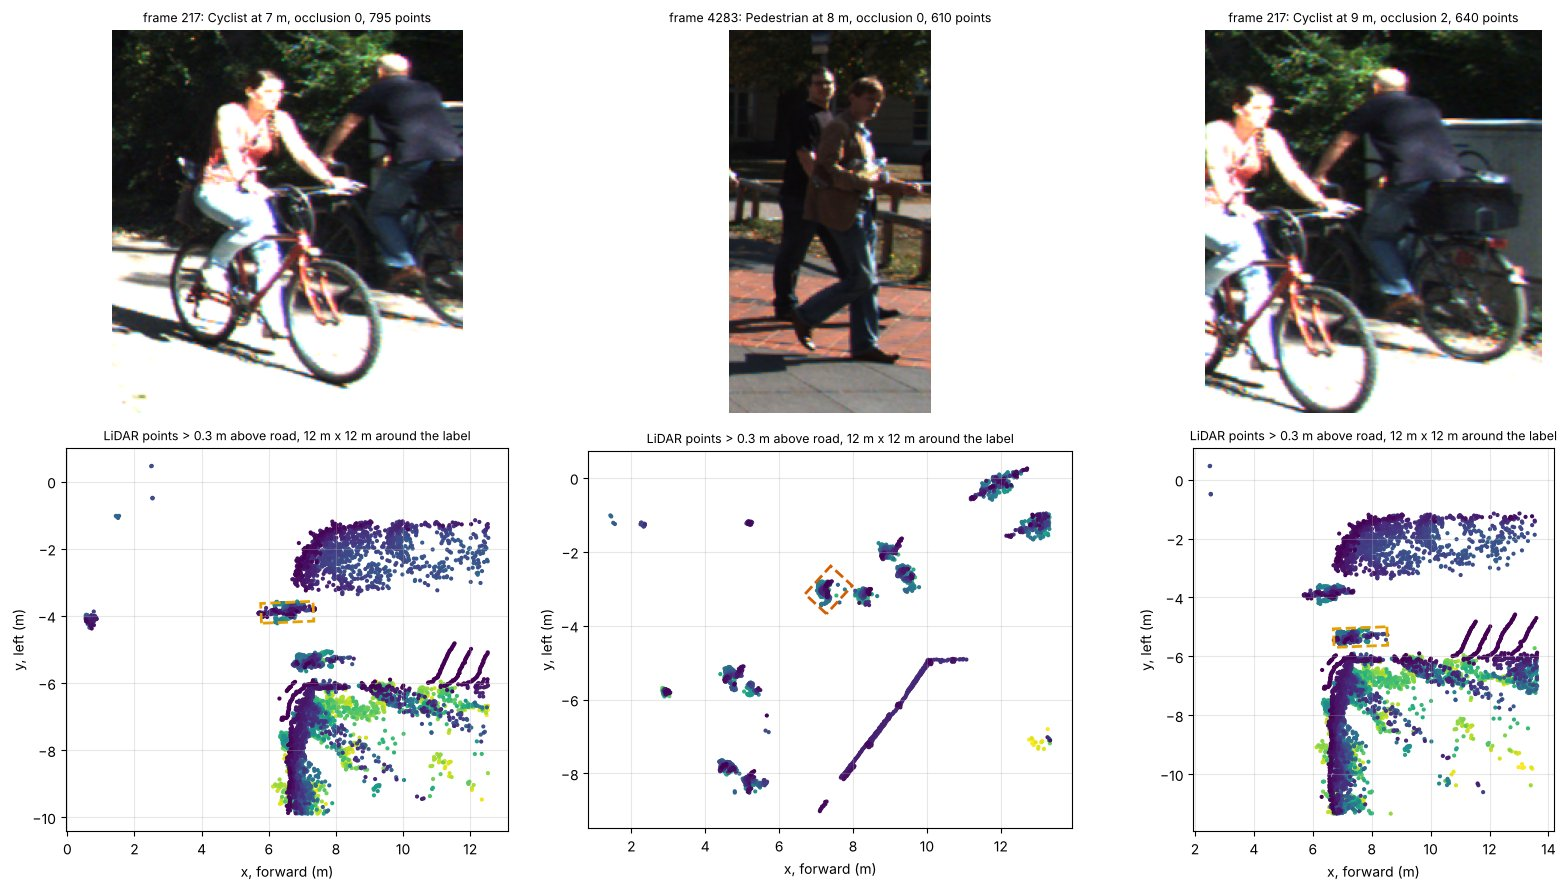

  Missed: frame 217, Cyclist at 7.4 m, occlusion 0, 795 points in box, 0 cluster(s) mostly inside the box
  Missed: frame 4283, Pedestrian at 7.6 m, occlusion 0, 610 points in box, 1 cluster(s) mostly inside the box
  Missed: frame 217, Cyclist at 9.1 m, occlusion 2, 640 points in box, 0 cluster(s) mostly inside the box


In [14]:
missed = ev[~ev['detected']].sort_values('distance_m').head(3)
if len(missed) == 0:
    print("No missed objects in these frames.")
else:
    fig, axes = plt.subplots(2, len(missed), figsize=(5.5 * len(missed), 9), squeeze=False)
    for k, (_, r) in enumerate(missed.iterrows()):
        fk = D.kitti_object(int(r['frame']))
        labs = [l for l in fk.labels if l['type'] in GROUP]
        l = min(labs, key=lambda l: abs(np.hypot(l['x'], l['z']) - r['distance_m']))
        pad = 20
        y1, y2, x1, x2 = max(int(l['y1']) - pad, 0), int(l['y2']) + pad, max(int(l['x1']) - pad, 0), int(l['x2']) + pad
        axes[0, k].imshow(fk.image[y1:y2, x1:x2]); axes[0, k].set_axis_off()
        axes[0, k].set_title(f"frame {int(r['frame'])}: {r['class']} at {r['distance_m']:.0f} m, occlusion {r['occluded']}, "
                             f"{r['lidar_points']} points", fontsize=9)
        fp = footprint_velo(fk, l); c0 = fp.mean(0)
        near = (np.abs(fk.points[:, 0] - c0[0]) < 6) & (np.abs(fk.points[:, 1] - c0[1]) < 6) & (fk.points[:, 2] > -1.4)
        axes[1, k].scatter(fk.points[near, 0], fk.points[near, 1], s=4, c=fk.points[near, 2], cmap='viridis')
        axes[1, k].add_patch(Polygon(fp, fill=False, edgecolor=CLASS_COLOURS[r['class']], lw=2, ls='--'))
        axes[1, k].set_aspect('equal'); axes[1, k].set_xlabel('x, forward (m)'); axes[1, k].set_ylabel('y, left (m)')
        axes[1, k].set_title('LiDAR points > 0.3 m above road, 12 m x 12 m around the label', fontsize=9)
    plt.tight_layout(); plt.show()
    for _, r in missed.iterrows():
        print(f"  Missed: frame {int(r['frame'])}, {r['class']} at {r['distance_m']:.1f} m, occlusion {r['occluded']}, "
              f"{r['lidar_points']} points in box, {r['n_clusters_on_object']} cluster(s) mostly inside the box")

## 6. LiDAR failure modes

| Failure mode | Mechanism | Typical effect | Seen in this notebook |
|---|---|---|---|
| Rain, fog, snow, spray | Backscatter and attenuation by droplets/flakes | Range loss, false near-range returns ("clutter") | No (KITTI is dry, daylight) |
| Dark / specular targets | Low or mirror-like reflectivity | Missing returns (black cars, wet road, glass) | Partly: near-zero reflectance returns (notebook 02) |
| Retro-reflectors | Very strong returns saturate the detector | Blooming: phantom points around signs and number plates | Strongest returns on number plates (notebook 02) |
| Sun and cross-talk | Ambient photons or other LiDARs | Noise points, spurious detections | No |
| Contamination | Mud, ice, insects on the window | Blind sectors | No |
| Motion distortion | Ego and object motion during the sweep | Smeared or duplicated objects unless de-skewed | Not visible in single frames |
| Calibration drift | Mechanical shocks, temperature | Mis-registered points, wrong fusion associations (section 4) | Measured in notebook 06 |
| Sparse long range and occlusion | 1/d² density, shadows behind objects | Small or hidden objects detected late or not at all | **Yes: section 5.4** |
| Clustering parameters | Fixed `eps`, `min_samples`, ground threshold | Merged pedestrians, split vehicles, lost low obstacles | **Yes: sections 5.2–5.5** |

## 7. Learned 3D detectors and the author's SOTIF work

Production stacks replace steps 3–4 by learned detectors that predict class, full (amodal) box, orientation and often velocity. **PointPillars** (Lang et al., 2019) encodes the points of each vertical BEV column ("pillar") with a small PointNet and runs a 2D CNN on the resulting pseudo-image; **CenterPoint** (Yin et al., 2021) detects object centres as heatmap peaks in BEV and regresses the box, which handles rotated objects well and extends naturally to tracking. Both are trained and evaluated on KITTI-style labels, so they inherit the label taxonomy: an object class absent from the training labels is not "detected" in a meaningful sense. A class-agnostic cluster path, as built here, is therefore still used as a cross-check.

The author's research applies the SOTIF view to such detectors: a simulation-based performance evaluation of deep-learning 3D detectors on a LiDAR point-cloud dataset generated for a SOTIF-related use case (Patel and Jung, VEHITS 2024), uncertainty evaluation to identify performance insufficiencies of ML-based LiDAR object detection (Patel and Jung, VEHITS 2026), and the representation of that uncertainty with Dempster–Shafer theory (Patel and Jung, CCIS 2026). The dataset, **SOTIF-PCOD**, is published on IEEE DataPort in KITTI format (CC BY 4.0; login required). The optional cell below loads it if you have downloaded it.

In [15]:
# Optional: the author's SOTIF-PCOD dataset (KITTI-format LiDAR from CARLA, doi:10.21227/j43q-z578, CC BY 4.0).
# Download it from IEEE DataPort (free account), unpack it and set the environment variable SOTIF_PCOD_DIR.
import os
from pathlib import Path
root = Path(os.environ.get('SOTIF_PCOD_DIR', ''))
bins = sorted(root.rglob('*.bin'))[:5] if str(root) and root.is_dir() else []
if bins:
    for b in bins:
        q = np.fromfile(b, dtype=np.float32).reshape(-1, 4)
        print(f"{b.relative_to(root)}: {len(q):,} points, range up to {np.hypot(q[:, 0], q[:, 1]).max():.0f} m")
    print("Try: run lidar_objects() on these scans and compare the cluster recall with the KITTI results above.")
else:
    print("SOTIF-PCOD not found (set SOTIF_PCOD_DIR to its folder). It is available at "
          "https://doi.org/10.21227/j43q-z578 (IEEE DataPort, CC BY 4.0, about 1.8 GB, login required).")

SOTIF-PCOD not found (set SOTIF_PCOD_DIR to its folder). It is available at https://doi.org/10.21227/j43q-z578 (IEEE DataPort, CC BY 4.0, about 1.8 GB, login required).


## Safety perspective

Each measured weakness pairs a scenario condition with a LiDAR **performance insufficiency**: distance and occlusion (section 5.4) reduce the points on an object, and fixed pipeline parameters decide whether those points still form an object. Conditions such as rain, fog, retro-reflectors, sun and contamination (section 6) are **triggering conditions** in the sense of ISO 21448:2022: the sensor is not broken, yet its output is insufficient for the intended function. Calibration drift is different: it is a degradation or fault and also belongs in the ISO 26262 analysis. For ML-based 3D detectors on top of the point cloud, ISO/PAS 8800:2024 adds questions about the training data (does it contain occluded children, dark cars, spray?) and about uncertainty estimation.

## In industry

**Work product:** the *LiDAR perception performance evaluation* that feeds the SOTIF analysis (identification of performance insufficiencies and triggering conditions, ISO 21448 clauses 6–7) and the verification report of the perception component. Typically produced by the **perception verification engineer** with the **SOTIF engineer**; reviewed by the safety manager and, for type approval, by the technical service.

What reviewers look for:
- Recall stratified by class, distance, occlusion and condition — never a single averaged number (compare the spread in section 5.4).
- Ground truth whose taxonomy and field of view are stated (KITTI: camera field of view only, no poles or debris), and an explicit rule for "unmatched" detections.
- Matching criteria (centre distance, IoU threshold) and their justification for the function: a braking function needs the nearest face, not an amodal box.
- Sensitivity of results to pipeline parameters (`eps`, `min_samples`, ground threshold) and to calibration.
- Each weak stratum traced to a triggering condition with an argued mitigation (another sensor, tracking, ODD restriction) or accepted residual risk.

Continue with: [04 Object detection](04_object_detection.ipynb) · [06 Sensor fusion](06_sensor_fusion.ipynb) · [04_SOTIF_ISO21448/02 — Triggering conditions](../04_SOTIF_ISO21448/02_triggering_conditions_and_scenarios.ipynb) · [06_AI_Safety_ISO_PAS_8800/02 — Uncertainty types](../06_AI_Safety_ISO_PAS_8800/02_uncertainty_types.ipynb).

## Key takeaways

- Pulsed ToF measures range from round-trip time (d = c·Δt/2); FMCW LiDAR additionally measures radial velocity per point.
- For an extended target, received power falls with 1/d²; for targets smaller than the beam footprint with 1/d⁴ — ranges must be quoted at a stated reflectivity.
- A real KITTI sweep has 64 unevenly spaced rings, a 0.18° azimuth step and fewer returns than the nominal 128,000 points; the ground near the car is blind within about 4 m.
- A classical pipeline (RANSAC ground plane, DBSCAN, minimum-area boxes) finds most labelled objects on real scans. Its misses are dominated by **segmentation**, not by sparsity: pedestrians walking in groups and cyclists next to fences merge into one cluster even at 7–10 m, while sparse cars beyond 45 m are the second failure pattern. Cluster boxes cover only the visible part of an object.
- Unmatched clusters are often real obstacles outside the label taxonomy: benchmark precision and safety relevance are different questions.
- Extrinsic calibration errors grow with range (≈ d·δψ): 1° of yaw error displaces a point at 50 m by ~0.9 m.
- Distance, occlusion, weather, dark targets, retro-reflectors and pipeline parameters are SOTIF-relevant conditions, not faults; learned detectors (PointPillars, CenterPoint) reduce but do not remove them.

## Self-assessment

1. A LiDAR pulse has a round-trip time of 3000 ns. How far away is the target?
2. Why do datasheets quote LiDAR range 'at 10 % reflectivity'? How does received power scale with distance for a small target?
3. Why does a real KITTI sweep contain fewer points than 64 × 360° / azimuth step?
4. The RANSAC plane gives a sensor height of about 1.7 m. Why is that a useful check, and when does a single plane fail?
5. In section 5.4, why is the median BEV IoU of correctly found cars much lower than 1, and why does that matter less for emergency braking than for a benchmark?
6. Give two reasons from section 5.5 why an object close to the vehicle can still be missed by the cluster pipeline.

<details>
<summary>Show answers</summary>

1. d = c·Δt/2 = 3×10⁸ × 3×10⁻⁶ / 2 ≈ 450 m (≈ 449.7 m with c = 299 792 458 m/s).
2. Because range depends strongly on target reflectivity; 10 % represents dark objects. For an extended target P_r ∝ 1/d², for a target smaller than the beam footprint P_r ∝ 1/d⁴.
3. Beams pointing at the sky or at distant, dark or specular surfaces return no echo above the detection threshold; KITTI also stores only valid returns.
4. It must match the known mounting height (1.73 m); a large deviation reveals a wrong calibration, a slope or a wrong plane (e.g. a wall). A single plane fails on hills, crests, ramps, kerbs and strong road camber.
5. KITTI boxes are amodal (whole object), while the cluster box covers only the faces hit by the LiDAR (often an L-shape of the rear and one side). For braking, the position of the nearest face and the free space in front of it matter most, and the visible points give exactly that.
6. Merging with a neighbour or a wall into one large cluster that is rejected by the size gate; too few points because of occlusion (below `min_samples`); parts below the height window or outside the crop; a ground plane that does not fit locally.

</details>

## References

1. Royo, S., Ballesta-Garcia, M. (2019). An Overview of Lidar Imaging Systems for Autonomous Vehicles. *Applied Sciences* 9(19), 4093. https://doi.org/10.3390/app9194093
2. Hecht, J. (2018). Lidar for Self-Driving Cars. *Optics & Photonics News* 29(1), 26–33. https://doi.org/10.1364/OPN.29.1.000026
3. Raj, T. et al. (2020). A Survey on LiDAR Scanning Mechanisms. *Electronics* 9(5), 741. https://doi.org/10.3390/electronics9050741
4. IEC 60825-1:2014. *Safety of laser products — Part 1: Equipment classification and requirements.*
5. ISO 8855:2011. *Road vehicles — Vehicle dynamics and road-holding ability — Vocabulary.*
6. ISO 21448:2022. *Road vehicles — Safety of the intended functionality.* https://www.iso.org/standard/77490.html
7. Geiger, A., Lenz, P., Stiller, C., Urtasun, R. (2013). Vision meets robotics: The KITTI dataset. *The International Journal of Robotics Research* 32(11), 1231–1237. https://doi.org/10.1177/0278364913491297
8. Geiger, A., Lenz, P., Urtasun, R. (2012). Are we ready for autonomous driving? The KITTI vision benchmark suite. *CVPR 2012*. https://doi.org/10.1109/CVPR.2012.6248074
9. Fischler, M. A., Bolles, R. C. (1981). Random Sample Consensus. *Communications of the ACM* 24(6), 381–395. https://doi.org/10.1145/358669.358692
10. Ester, M., Kriegel, H.-P., Sander, J., Xu, X. (1996). A Density-Based Algorithm for Discovering Clusters in Large Spatial Databases with Noise. *Proc. KDD-96*, 226–231.
11. Lang, A. H., Vora, S., Caesar, H., Zhou, L., Yang, J., Beijbom, O. (2019). PointPillars: Fast Encoders for Object Detection From Point Clouds. *CVPR 2019*. https://doi.org/10.1109/CVPR.2019.01298
12. Yin, T., Zhou, X., Krähenbühl, P. (2021). Center-based 3D Object Detection and Tracking. *CVPR 2021*. https://doi.org/10.1109/CVPR46437.2021.01161
13. Patel, M., Jung, R. (2024). Simulation-Based Performance Evaluation of 3D Object Detection Methods with Deep Learning for a LiDAR Point Cloud Dataset in a SOTIF-related Use Case. *VEHITS 2024*, 415–426. https://doi.org/10.5220/0012707300003702
14. Patel, M., Jung, R. (2026). Uncertainty Evaluation to Support Safety of the Intended Functionality Analysis for Identifying Performance Insufficiencies in ML-Based LiDAR Object Detection. *VEHITS 2026*, 154–167. https://doi.org/10.5220/0014967200004030
15. Patel, M., Jung, R. (2026). Uncertainty Representation in a SOTIF-Related Use Case with Dempster-Shafer Theory for LiDAR Sensor-Based Object Detection. *CCIS*, Springer, 178–193. https://doi.org/10.1007/978-3-032-23187-1_10
16. Patel, M. (2024). SOTIF PCOD [dataset]. IEEE DataPort, CC BY 4.0. https://doi.org/10.21227/j43q-z578

---
**Navigation:** ← [02 Sensor modalities](02_sensor_modalities.ipynb) · [Module index](README.md) · [04 Object detection](04_object_detection.ipynb) →